In [1]:

import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter


for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    try:
        nltk.download(resource, quiet=True)
    except Exception:
        pass

from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist
from nltk.stem import PorterStemmer, WordNetLemmatizer

STOP_WORDS = set(stopwords.words("english"))

I find the concept of parallel universes fascinating because it challenges the way we understand reality. In The Hidden Reality, Brian Greene explores the possibility that our universe may be only one among many universes that exist. Some theories suggest that different universes could have different physical laws or entirely different versions of reality. Although these ideas are difficult to prove experimentally, they encourage scientists to question what lies beyond our observable universe. I enjoy reading about such theories because they connect physics, mathematics, and philosophy while raising exciting questions about our place in the cosmos.
Lowercase text:
 i find the concept of parallel universes fascinating because it challenges the way we understand reality. in the hidden reality, brian greene explores the possibility that our universe may be only one among many universes that exist. some theories suggest that different universes could have different physical laws or entirel

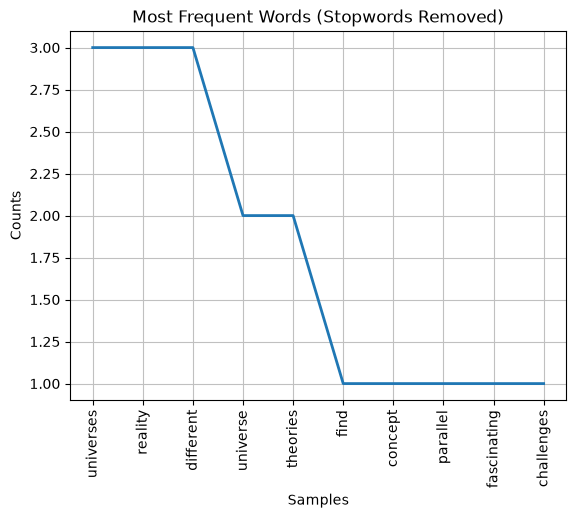

In [2]:
#q1

paragraph = (
    "I find the concept of parallel universes fascinating because it "
    "challenges the way we understand reality. In The Hidden Reality, "
    "Brian Greene explores the possibility that our universe may be "
    "only one among many universes that exist. Some theories suggest "
    "that different universes could have different physical laws or "
    "entirely different versions of reality. Although these ideas are "
    "difficult to prove experimentally, they encourage scientists to "
    "question what lies beyond our observable universe. I enjoy reading "
    "about such theories because they connect physics, mathematics, "
    "and philosophy while raising exciting questions about our place "
    "in the cosmos."
)

print(paragraph)

lower_text = paragraph.lower()
clean_text = re.sub(r"[^a-zA-Z\s]", "", lower_text)
print("Lowercase text:\n", lower_text)
print("\nPunctuation removed:\n", clean_text)


word_tokens = word_tokenize(paragraph)
sentence_tokens = sent_tokenize(paragraph)

print("Word tokens:")
print(word_tokens)
print("\nSentence tokens:")
for i, sentence in enumerate(sentence_tokens, start=1):
    print(f"{i}. {sentence}")

split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)

print("split():", split_tokens)
print("\nword_tokenize():", nltk_tokens)
print("\nNumber of tokens using split():", len(split_tokens))
print("Number of tokens using word_tokenize():", len(nltk_tokens))

tokens_lower = [token.lower() for token in word_tokenize(clean_text) if token.isalpha()]
filtered_tokens = [token for token in tokens_lower if token not in STOP_WORDS]
print("Tokens after stopword removal:")
print(filtered_tokens)

frequency = FreqDist(filtered_tokens)
print("Word frequencies:")
for word, count in frequency.most_common():
    print(f"{word}: {count}")

if frequency:
    frequency.plot(10, title="Most Frequent Words (Stopwords Removed)")
    plt.show()

In [4]:
#q2


alphabetic_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
print("Alphabetic words:")
print(alphabetic_words)


q2_tokens = [word for word in alphabetic_words if word not in STOP_WORDS]
print("\nAfter stopword removal:")
print(q2_tokens)


stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(word) for word in q2_tokens]


lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(word) for word in q2_tokens]

comparison = pd.DataFrame({
    "Original": q2_tokens,
    "Stemmed": stemmed_words,
    "Lemmatized (noun default)": lemmatized_words
})
display(comparison)
print("Stemming  chops word endings and may produce nonwords ). Lemmatization looks for a dictionary base form. Stemming is fast and useful when approximate matching is enough; lemmatization is preferable when readable,  meaningful base forms matter")

Alphabetic words:
['i', 'find', 'the', 'concept', 'of', 'parallel', 'universes', 'fascinating', 'because', 'it', 'challenges', 'the', 'way', 'we', 'understand', 'reality', 'in', 'the', 'hidden', 'reality', 'brian', 'greene', 'explores', 'the', 'possibility', 'that', 'our', 'universe', 'may', 'be', 'only', 'one', 'among', 'many', 'universes', 'that', 'exist', 'some', 'theories', 'suggest', 'that', 'different', 'universes', 'could', 'have', 'different', 'physical', 'laws', 'or', 'entirely', 'different', 'versions', 'of', 'reality', 'although', 'these', 'ideas', 'are', 'difficult', 'to', 'prove', 'experimentally', 'they', 'encourage', 'scientists', 'to', 'question', 'what', 'lies', 'beyond', 'our', 'observable', 'universe', 'i', 'enjoy', 'reading', 'about', 'such', 'theories', 'because', 'they', 'connect', 'physics', 'mathematics', 'and', 'philosophy', 'while', 'raising', 'exciting', 'questions', 'about', 'our', 'place', 'in', 'the', 'cosmos']

After stopword removal:
['find', 'concept', 

,Original,Stemmed,Lemmatized (noun default)
0,find,find,find
1,concept,concept,concept
2,parallel,parallel,parallel
3,universes,univers,universe
4,fascinating,fascin,fascinating
5,challenges,challeng,challenge
6,way,way,way
7,understand,understand,understand
8,reality,realiti,reality
9,hidden,hidden,hidden


Stemming  chops word endings and may produce nonwords ). Lemmatization looks for a dictionary base form. Stemming is fast and useful when approximate matching is enough; lemmatization is preferable when readable,  meaningful base forms matter


In [6]:
#q3
texts = [
    "Artificial intelligence helps doctors analyze medical images.",
    "Renewable energy reduces pollution and supports a cleaner environment.",
    "Online learning gives students flexible access to educational resources."
]

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer


count_vectorizer = CountVectorizer()
bow_matrix = count_vectorizer.fit_transform(texts)
bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=count_vectorizer.get_feature_names_out(),
    index=[f"Text {i}" for i in range(1, len(texts) + 1)]
)
print("Bag of Words matrix:")
display(bow_df)


tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=[f"Text {i}" for i in range(1, len(texts) + 1)]
)
print("TF-IDF matrix (rounded):")
display(tfidf_df.round(3))


feature_names = tfidf_vectorizer.get_feature_names_out()
print("Top 3 TF-IDF keywords per text:")
for i, row in enumerate(tfidf_matrix.toarray(), start=1):
    top_indices = row.argsort()[::-1][:3]
    print(f"Text {i}: " + ", ".join(f"{feature_names[j]} ({row[j]:.3f})" for j in top_indices))                

Bag of Words matrix:


,access,analyze,and,artificial,cleaner,doctors,educational,energy,environment,flexible,...,learning,medical,online,pollution,reduces,renewable,resources,students,supports,to
Text 1,0,1,0,1,0,1,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
Text 2,0,0,1,0,1,0,0,1,1,0,...,0,0,0,1,1,1,0,0,1,0
Text 3,1,0,0,0,0,0,1,0,0,1,...,1,0,1,0,0,0,1,1,0,1


TF-IDF matrix (rounded):


,access,analyze,and,artificial,cleaner,doctors,educational,energy,environment,flexible,...,learning,medical,online,pollution,reduces,renewable,resources,students,supports,to
Text 1,0.000,0.378,0.000,0.378,0.000,0.378,0.000,0.000,0.000,0.000,...,0.000,0.378,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Text 2,0.000,0.000,0.354,0.000,0.354,0.000,0.000,0.354,0.354,0.000,...,0.000,0.000,0.000,0.354,0.354,0.354,0.000,0.000,0.354,0.000
Text 3,0.333,0.000,0.000,0.000,0.000,0.000,0.333,0.000,0.000,0.333,...,0.333,0.000,0.333,0.000,0.000,0.000,0.333,0.333,0.000,0.333


Top 3 TF-IDF keywords per text:
Text 1: helps (0.378), doctors (0.378), analyze (0.378)
Text 2: supports (0.354), pollution (0.354), reduces (0.354)
Text 3: to (0.333), students (0.333), resources (0.333)


In [7]:
technology_a = (
    "Artificial intelligence learns patterns from data. "
    "AI systems can classify images, translate languages, and answer questions. "
    "They often improve when trained on useful examples. "
    "AI applications raise questions about privacy, bias, and transparency."
)
technology_b = (
    "Blockchain stores records in linked blocks. "
    "A distributed network helps participants verify transactions. "
    "Cryptographic methods make past records difficult to alter. "
    "Blockchain applications include digital assets and supply-chain tracking."
)

def preprocess(text):
    words = re.findall(r"[a-zA-Z]+", text.lower())
    return [w for w in words if w not in STOP_WORDS]

tokens_a = preprocess(technology_a)
tokens_b = preprocess(technology_b)
print("Technology A tokens:", tokens_a)
print("\nTechnology B tokens:", tokens_b)


set_a, set_b = set(tokens_a), set(tokens_b)
jaccard = len(set_a & set_b) / len(set_a | set_b) if (set_a | set_b) else 0.0
print(f"\nJaccard similarity: {jaccard:.4f}")


from sklearn.metrics.pairwise import cosine_similarity
tfidf_pair = TfidfVectorizer()
pair_matrix = tfidf_pair.fit_transform([technology_a, technology_b])
cosine = cosine_similarity(pair_matrix[0:1], pair_matrix[1:2])[0, 0]
print(f"Cosine similarity (TF-IDF): {cosine:.4f}")

Technology A tokens: ['artificial', 'intelligence', 'learns', 'patterns', 'data', 'ai', 'systems', 'classify', 'images', 'translate', 'languages', 'answer', 'questions', 'often', 'improve', 'trained', 'useful', 'examples', 'ai', 'applications', 'raise', 'questions', 'privacy', 'bias', 'transparency']

Technology B tokens: ['blockchain', 'stores', 'records', 'linked', 'blocks', 'distributed', 'network', 'helps', 'participants', 'verify', 'transactions', 'cryptographic', 'methods', 'make', 'past', 'records', 'difficult', 'alter', 'blockchain', 'applications', 'include', 'digital', 'assets', 'supply', 'chain', 'tracking']

Jaccard similarity: 0.0217
Cosine similarity (TF-IDF): 0.0444


,Review,Positive score,Neutral score,Negative score,Compound polarity,Sentiment
0,The headphones sound excellent and the battery...,0.291,0.709,0.000,0.572,Positive
1,Customer support was helpful and delivery was ...,0.562,0.438,0.000,0.772,Positive
2,The app is easy to use and works smoothly.,0.266,0.734,0.000,0.440,Positive
3,The package arrived late and the product was d...,0.000,0.734,0.266,-0.440,Negative
4,The service was disappointing and nobody answe...,0.000,0.565,0.435,-0.660,Negative
5,The battery drains quickly and the build quali...,0.000,1.000,0.000,0.000,Neutral
6,The item arrived today.,0.000,1.000,0.000,0.000,Neutral
7,The product has a screen and two buttons.,0.000,1.000,0.000,0.000,Neutral


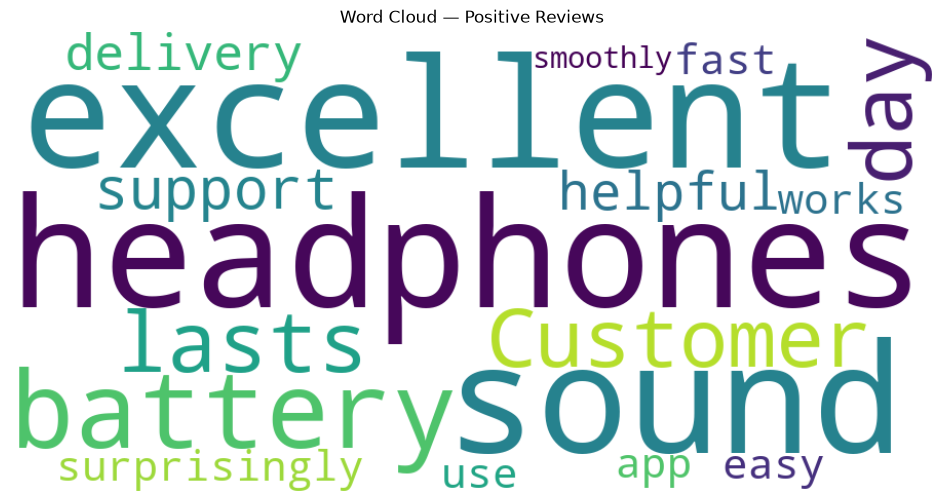

In [15]:

views = [
    "The headphones sound excellent and the battery lasts all day.",
    "Customer support was helpful and delivery was surprisingly fast.",
    "The app is easy to use and works smoothly.",
    "The package arrived late and the product was damaged.",
    "The service was disappointing and nobody answered my complaint.",
    "The battery drains quickly and the build quality feels cheap.",
    "The item arrived today.",
    "The product has a screen and two buttons."
]

try:
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
except ImportError:

    raise ImportError("Install vaderSentiment with: %pip install vaderSentiment")

analyzer = SentimentIntensityAnalyzer()

def classify_sentiment(compound, positive_threshold=0.05, negative_threshold=-0.05):
    if compound >= positive_threshold:
        return "Positive"
    elif compound <= negative_threshold:
        return "Negative"
    return "Neutral"

review_results = []
for review in reviews:
    scores = analyzer.polarity_scores(review)
    label = classify_sentiment(scores["compound"])
    review_results.append({
        "Review": review,
        "Positive score": scores["pos"],
        "Neutral score": scores["neu"],
        "Negative score": scores["neg"],
        "Compound polarity": scores["compound"],
        "Sentiment": label
    })

review_df = pd.DataFrame(review_results)
display(review_df.round(3))


from wordcloud import WordCloud

positive_reviews = review_df.loc[review_df["Sentiment"] == "Positive", "Review"].tolist()
if positive_reviews:
    positive_text = " ".join(positive_reviews)
    cloud = WordCloud(width=900, height=450, background_color="white").generate(positive_text)
    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud — Positive Reviews")
    plt.show()
else:
    print("No positive reviews were classified, so a word cloud could not be generated.")

Training words: 87
Technology changes the way people learn and communicate. Students use digital tools to explore new ideas and practise difficult skills. Machine learning systems find patterns in examples and use those patterns to make predictions. Good data helps a model learn useful relationships, while noisy data can lead to mistakes. Developers test their systems, measure performance, and improve weak areas. Responsible technology also protects privacy, reduces unfair bias, and explains important decisions. Learning takes patience, experimentation, and regular practice. Small projects help beginners connect theory with real applications.
Vocabulary size: 75
Training examples: 86
Input shape: (86, 86)
Target shape: (86, 75)


C:\Users\HP\miniconda3\envs\myenv\Lib\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Training complete.


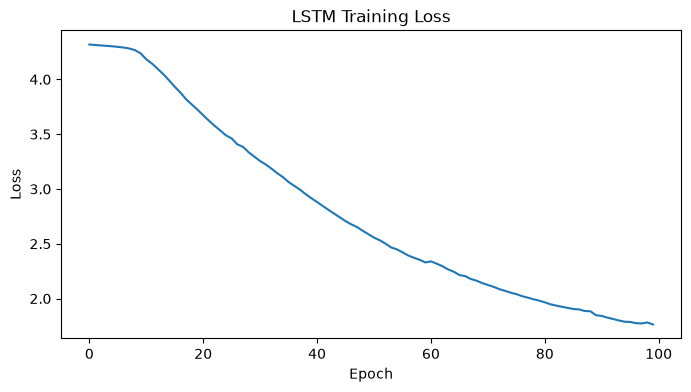

Generated text (seed = 'technology' ):
technology the the changes way students people students communicate learn digital digital explore ideas digital and and in new practise machine skills ideas difficult skills patterns use examples those patterns use to to systems a make


In [19]:
training_text = (
    "Technology changes the way people learn and communicate. "
    "Students use digital tools to explore new ideas and practise difficult skills. "
    "Machine learning systems find patterns in examples and use those patterns to make predictions. "
    "Good data helps a model learn useful relationships, while noisy data can lead to mistakes. "
    "Developers test their systems, measure performance, and improve weak areas. "
    "Responsible technology also protects privacy, reduces unfair bias, and explains important decisions. "
    "Learning takes patience, experimentation, and regular practice. "
    "Small projects help beginners connect theory with real applications."
)
print("Training words:", len(training_text.split()))
print(training_text)


import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

tokenizer = Tokenizer(oov_token="<OOV>")
tokenizer.fit_on_texts([training_text])
sequences = tokenizer.texts_to_sequences([training_text])[0]
total_words = len(tokenizer.word_index) + 1

input_sequences = []
for i in range(1, len(sequences)):
    input_sequences.append(sequences[:i + 1])

max_sequence_len = max(len(seq) for seq in input_sequences)
padded_sequences = pad_sequences(input_sequences, maxlen=max_sequence_len, padding="pre")
X = padded_sequences[:, :-1]
y = padded_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

print("Vocabulary size:", total_words)
print("Training examples:", X.shape[0])
print("Input shape:", X.shape)
print("Target shape:", y.shape)

model = Sequential([
    Embedding(input_dim=total_words, output_dim=32, input_length=X.shape[1]),
    LSTM(64),
    Dense(total_words, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()
history = model.fit(X, y, epochs=100, verbose=0)
print("Training complete.")
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"])
plt.title("LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()
def generate_text(seed_text, next_words=20, temperature=0.8):
    generated = seed_text.lower()
    for _ in range(next_words):
        seq = tokenizer.texts_to_sequences([generated])[0]
        seq = pad_sequences([seq], maxlen=X.shape[1], padding="pre")
        probabilities = model.predict(seq, verbose=0)[0]


        probabilities = np.asarray(probabilities).astype("float64")
        probabilities = np.log(probabilities + 1e-10) / temperature
        probabilities = np.exp(probabilities - np.max(probabilities))
        probabilities = probabilities / probabilities.sum()
        next_index = np.random.choice(len(probabilities), p=probabilities)

        next_word = next((word for word, index in tokenizer.word_index.items()
                          if index == next_index), "")
        if not next_word or next_word == "<OOV>":
            continue
        generated += " " + next_word
    return generated

seed = "technology"
print("Generated text (seed =", repr(seed), "):")
print(generate_text(seed, next_words=35))